# Test evaluation

This notebook applies Sections 4.5 to 4.7 of the evaluation protocol. The naive forecast, the HAR regression and the ARIMA and Random Forest configurations selected on the validation period forecast every session of the test period (2024–2025) one day ahead.

**Nothing is chosen here.** The configurations are read from `results/selected_models.json`, which was fixed before this notebook was written. The comparisons, the significance tests and the split into large-move and ordinary days were all specified in advance.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import diebold_mariano_test

# The notebook lives in notebooks/, one level below the project root.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from vixforecast.data import SPLITS, load_vix
from vixforecast.evaluation import mae, rmse, walk_forward
from vixforecast.models import Arima, Naive, forest, har

RESULTS = ROOT / "results"
FIGURES = ROOT / "report" / "figures"

INK, MUTED, GRID = "#172C36", "#52636A", "#DDE3E6"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": MUTED,
    "axes.edgecolor": GRID, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11,
})

## 1. Data and selected models

In [2]:
selected = json.loads((RESULTS / "selected_models.json").read_text(encoding="utf-8"))
START, END = SPLITS["test"]

closes = load_vix()
actual = closes.loc[START:END]

print(f"Test targets: {actual.index[0].date()} to {actual.index[-1].date()} ({len(actual)})")
print(json.dumps(selected, indent=2))

Test targets: 2024-01-02 to 2025-12-31 (502)
{
  "selected_on": "validation period, 2022-01-03 to 2023-12-29",
  "criterion": "lowest validation RMSE",
  "arima": {
    "p": 1,
    "d": 0,
    "q": 0
  },
  "random_forest": {
    "target": "change",
    "features": "har",
    "min_samples_leaf": 50,
    "split_features": "third"
  }
}


## 2. Forecasts

Each model is re-estimated before the first forecast of each calendar month on all closes before that date, so the validation years are part of the estimation sample from the start. Every forecast uses only closes dated before its target.

In [3]:
ARIMA_NAME = "ARIMA({p},{d},{q})".format(**selected["arima"])

models = {
    "Naive": Naive(),
    "HAR": har(),
    ARIMA_NAME: Arima(**selected["arima"]),
    "Random Forest": forest(**selected["random_forest"]),
}

forecasts = pd.DataFrame({
    name: walk_forward(closes, model, START, END) for name, model in models.items()
})
errors = forecasts.rsub(actual, axis=0)  # actual minus forecast

print(f"{len(forecasts)} forecasts per model")
print(f"ARIMA re-estimations that did not converge: {len(models[ARIMA_NAME].failed_fits)}")

502 forecasts per model
ARIMA re-estimations that did not converge: 0


## 3. Accuracy

MAE and RMSE are in VIX index points. The last two columns divide by the naive forecast's value, so a number below 1 means lower error than naive.

In [4]:
metrics = pd.DataFrame({
    "RMSE": {name: rmse(actual, forecasts[name]) for name in forecasts},
    "MAE": {name: mae(actual, forecasts[name]) for name in forecasts},
})
metrics["RMSE / naive"] = metrics["RMSE"] / metrics.loc["Naive", "RMSE"]
metrics["MAE / naive"] = metrics["MAE"] / metrics.loc["Naive", "MAE"]
metrics.round(4)

,RMSE,MAE,RMSE / naive,MAE / naive
Naive,2.0656,1.0975,1.0000,1.0000
HAR,2.0362,1.0983,0.9858,1.0008
"ARIMA(1,0,0)",2.0361,1.0910,0.9857,0.9941
Random Forest,2.0529,1.0929,0.9939,0.9959


**Reading.** All three fitted models have a lower RMSE than the naive forecast, but by small margins: ARIMA(1,0,0) and HAR by 1.4%, Random Forest by 0.6%. On MAE the differences are smaller still: ARIMA is 0.6% lower than naive, Random Forest 0.4% lower and HAR 0.1% higher.

Errors are larger than in the validation period for every forecast (naive RMSE 2.07 against 1.43) because the test period contains bigger spikes. Relative to naive, the picture is similar to validation: the selected models kept their small advantage in RMSE, and the order among them changed, with ARIMA and HAR now ahead of Random Forest.

## 4. Are the differences statistically distinguishable?

The Diebold–Mariano test asks whether two forecasts have the same expected loss. It uses the Harvey–Leybourne–Newbold small-sample correction and a Newey–West variance with 8 lags. Tests are two-sided.

`mean loss difference` is the first forecast's average loss minus the second's: a negative value means the first forecast was more accurate on this sample.

In [5]:
PAIRS = [
    (ARIMA_NAME, "Naive"),
    ("HAR", "Naive"),
    ("Random Forest", "Naive"),
    ("Random Forest", ARIMA_NAME),
    ("Random Forest", "HAR"),
]
LOSSES = {"squared error": ("mse", lambda e: e ** 2), "absolute error": ("mae", np.abs)}

rows = []
for first, second in PAIRS:
    for loss_name, (criterion, loss) in LOSSES.items():
        test = diebold_mariano_test(
            actual.to_numpy(), forecasts[first].to_numpy(), forecasts[second].to_numpy(),
            lags=8, criterion=criterion, harvey_adj=True, horizon=1,
        )
        rows.append({
            "comparison": f"{first} vs {second}",
            "loss": loss_name,
            "mean loss difference": (loss(errors[first]) - loss(errors[second])).mean(),
            "DM statistic": test.statistic,
            "p-value": test.pvalue,
        })

dm_tests = pd.DataFrame(rows)
dm_tests.round(4)

,comparison,loss,mean loss difference,DM statistic,p-value
0,"ARIMA(1,0,0) vs Naive",squared error,-0.1209,-1.8444,0.0657
1,"ARIMA(1,0,0) vs Naive",absolute error,-0.0065,-0.8924,0.3726
2,HAR vs Naive,squared error,-0.1206,-1.0049,0.3154
3,HAR vs Naive,absolute error,0.0009,0.0726,0.9422
4,Random Forest vs Naive,squared error,-0.0522,-0.9433,0.3460
5,Random Forest vs Naive,absolute error,-0.0045,-0.4886,0.6254
6,"Random Forest vs ARIMA(1,0,0)",squared error,0.0687,1.6884,0.0920
7,"Random Forest vs ARIMA(1,0,0)",absolute error,0.0019,0.3303,0.7413
8,Random Forest vs HAR,squared error,0.0684,0.8299,0.4070
9,Random Forest vs HAR,absolute error,-0.0054,-0.5391,0.5901


**Reading.** None of the ten tests rejects equal accuracy at the 5% level. The two smallest p-values are for ARIMA against naive under squared-error loss (0.066) and for Random Forest against ARIMA under squared-error loss (0.092, with ARIMA the more accurate). Under absolute-error loss every p-value is 0.37 or higher.

On this evidence, no fitted model can be said to be more accurate than the naive forecast, and Random Forest cannot be distinguished from ARIMA or HAR.

Two cautions from the protocol apply. The naive forecast is a special case of the HAR regression, and tests of this type reject too rarely for nested models. The loss differences are also dominated by a few days, which makes the test imprecise. "Not distinguishable" therefore does not mean "shown to be equal".

## 5. Where do the errors come from?

Test days are ranked by the size of the realised move, |today's close − yesterday's close|. The 5% of days with the largest moves are compared with the remaining 95%.

In [6]:
move = (actual - closes.shift(1).loc[actual.index]).abs()
n_large = int(np.ceil(0.05 * len(actual)))
large_days = move.sort_values(ascending=False).index[:n_large]
is_large = actual.index.isin(large_days)

print(f"Large-move days: {is_large.sum()}; other days: {(~is_large).sum()}")
print(f"Smallest move among the large-move days: {move[is_large].min():.2f} points")
move.sort_values(ascending=False).head(5).round(2).to_frame("absolute move (index points)")

Large-move days: 26; other days: 476
Smallest move among the large-move days: 3.32 points


,absolute move (index points)
date,
2025-04-09,18.71
2025-04-04,15.29
2024-08-05,15.18
2024-12-18,11.75
2024-08-06,10.86


In [7]:
concentration = pd.DataFrame({
    "RMSE, large-move days": {n: rmse(actual[is_large], forecasts.loc[is_large, n]) for n in forecasts},
    "RMSE, other days": {n: rmse(actual[~is_large], forecasts.loc[~is_large, n]) for n in forecasts},
    "MAE, large-move days": {n: mae(actual[is_large], forecasts.loc[is_large, n]) for n in forecasts},
    "MAE, other days": {n: mae(actual[~is_large], forecasts.loc[~is_large, n]) for n in forecasts},
    "share of squared error from large-move days": (errors[is_large] ** 2).sum() / (errors ** 2).sum(),
})
concentration.round(4)

,"RMSE, large-move days","RMSE, other days","MAE, large-move days","MAE, other days",share of squared error from large-move days
Naive,7.7957,1.0863,6.5862,0.7976,0.7377
HAR,7.6378,1.0891,6.4598,0.8055,0.7287
"ARIMA(1,0,0)",7.7015,1.0641,6.5229,0.7943,0.7410
Random Forest,7.7794,1.0672,6.5819,0.7931,0.7437


**Reading.** The 26 large-move days are 5% of the test period and produce 73% to 74% of the total squared error of every forecast. RMSE is about 7.6 to 7.8 points on those days and about 1.07 to 1.09 on the others.

No model anticipates the large moves: on those days the four forecasts are within about 2% of one another. The HAR regression's advantage over naive comes entirely from the large-move days; on the other 476 days its RMSE and MAE are slightly higher than naive's. ARIMA and Random Forest are slightly better than naive in both groups.

The next figure follows each fitted model through the test period. It adds up, day by day, the model's squared error minus the naive forecast's squared error. When a line falls, the model is doing better than naive; when it rises, worse. A sudden step is a single day that mattered a lot.

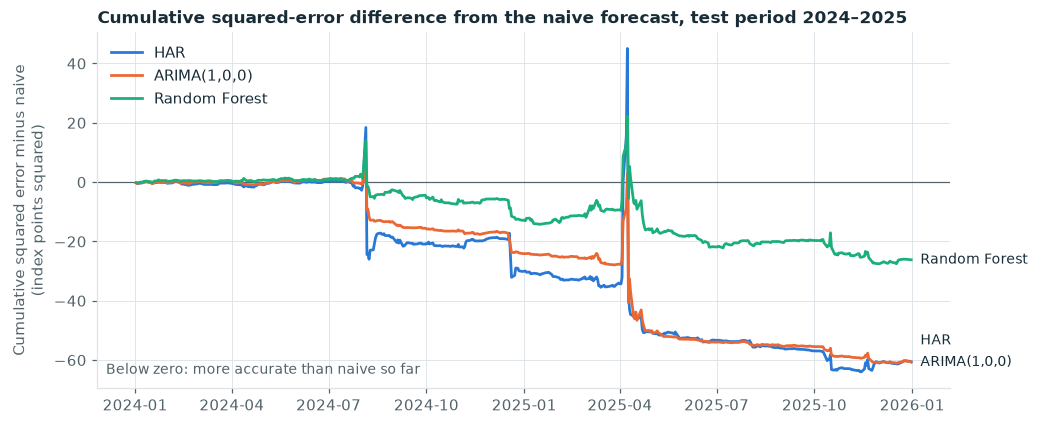

In [8]:
squared_gap = (errors.drop(columns="Naive") ** 2).sub(errors["Naive"] ** 2, axis=0).cumsum()
COLOURS = {"HAR": "#2a78d6", ARIMA_NAME: "#eb6834", "Random Forest": "#1baf7a"}

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.axhline(0, color=MUTED, linewidth=0.8)
for name, colour in COLOURS.items():
    ax.plot(squared_gap.index, squared_gap[name], color=colour, linewidth=1.8, label=name)

# Label each line at its right end, nudging labels apart where lines finish close together.
low, high = ax.get_ylim()
label_height = -np.inf
for name, value in squared_gap.iloc[-1].sort_values().items():
    label_height = max(value, label_height + 0.06 * (high - low))
    ax.annotate(name, (squared_gap.index[-1], label_height),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)

ax.set_ylabel("Cumulative squared error minus naive\n(index points squared)")
ax.set_title("Cumulative squared-error difference from the naive forecast, test period 2024–2025")
ax.text(0.01, 0.04, "Below zero: more accurate than naive so far", transform=ax.transAxes, color=MUTED, fontsize=9)
ax.legend(frameon=False, loc="upper left")
fig.savefig(FIGURES / "test_cumulative_squared_error.png")
plt.show()

**Reading.** For the first seven months the lines stay at zero: the fitted models are no different from naive. The gap opens in a few steps, around 5–6 August 2024, 18–20 December 2024 and 4–9 April 2025.

The pattern is the same each time. Each fitted model pulls its forecast slightly back towards the usual level of the VIX. While the VIX is still jumping upwards this makes the model worse than naive, and the line rises. On the day the VIX falls back it makes the model better, and the line drops. Two days, 6 August 2024 and 9 April 2025, account for most of the gain over the whole period.

## 6. Save the results

In [9]:
metrics.round(6).to_csv(RESULTS / "test_metrics.csv", index_label="forecast", lineterminator="\n")
dm_tests.round(6).to_csv(RESULTS / "test_dm_tests.csv", index=False, lineterminator="\n")
concentration.round(6).to_csv(RESULTS / "test_error_concentration.csv", index_label="forecast", lineterminator="\n")
print("Saved test_metrics.csv, test_dm_tests.csv and test_error_concentration.csv")

Saved test_metrics.csv, test_dm_tests.csv and test_error_concentration.csv


## 7. Summary

**Main question.** Random Forest does not improve on ARIMA or on the naive forecast in a way this test can distinguish. Its RMSE is 0.6% below naive and 0.8% above ARIMA(1,0,0), and neither difference is statistically significant. The two simple linear models, ARIMA(1,0,0) and HAR, did at least as well as the Random Forest.

**Secondary question.** Forecast errors are heavily concentrated. Five percent of days produce about three quarters of the squared error, and the differences between models arise almost entirely around three episodes of sharp VIX movement.

**Limits of this result.** It comes from one two-year test window, uses only the history of the VIX and covers a one-session horizon. The fitted models' advantage depends on how quickly spikes reversed in this particular period.